In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [2]:
df = pd.read_csv(r"C:/Users/NEXUS/Downloads/emails.csv")
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [3]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB


Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64

In [4]:
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

In [5]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [6]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

In [8]:
print("Accuracy:", accuracy_score(y_test, knn_pred))
print(confusion_matrix(y_test, knn_pred))
print(classification_report(y_test, knn_pred))

Accuracy: 0.8454106280193237
[[593 146]
 [ 14 282]]
              precision    recall  f1-score   support

           0       0.98      0.80      0.88       739
           1       0.66      0.95      0.78       296

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.83      1035
weighted avg       0.89      0.85      0.85      1035



In [9]:
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

In [10]:
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(confusion_matrix(y_test, svm_pred))
print(classification_report(y_test, svm_pred))

Accuracy: 0.9468599033816425
[[707  32]
 [ 23 273]]
              precision    recall  f1-score   support

           0       0.97      0.96      0.96       739
           1       0.90      0.92      0.91       296

    accuracy                           0.95      1035
   macro avg       0.93      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



In [11]:
knn_pred = knn.predict(X_test)
svm_pred = svm.predict(X_test)

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# KNN
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred)
knn_recall = recall_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred)
# SVM
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

In [13]:
comparison = pd.DataFrame({'Model': ['KNN', 'SVM'],'Accuracy': [knn_accuracy, svm_accuracy],'Precision': [knn_precision, svm_precision],'Recall': [knn_recall, svm_recall],'F1-Score': [knn_f1, svm_f1]})

In [15]:
comparison.head()

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.845411,0.658879,0.952703,0.779006
1,SVM,0.946860,0.895082,0.922297,0.908486


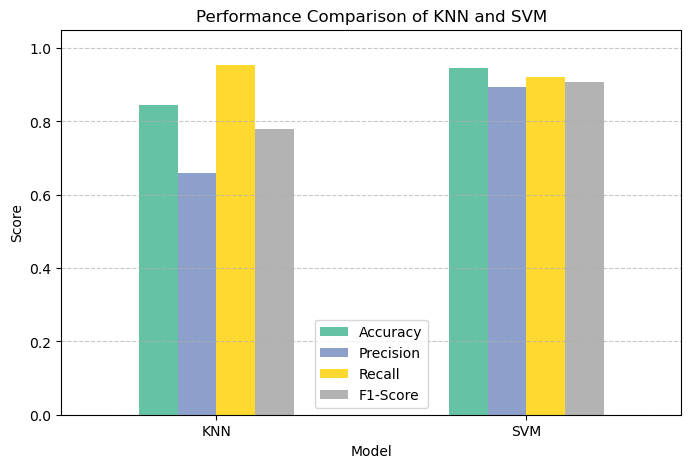

In [16]:
import matplotlib.pyplot as plt
comparison.set_index('Model').plot(kind='bar',figsize=(8, 5),colormap='Set2')
plt.title("Performance Comparison of KNN and SVM")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

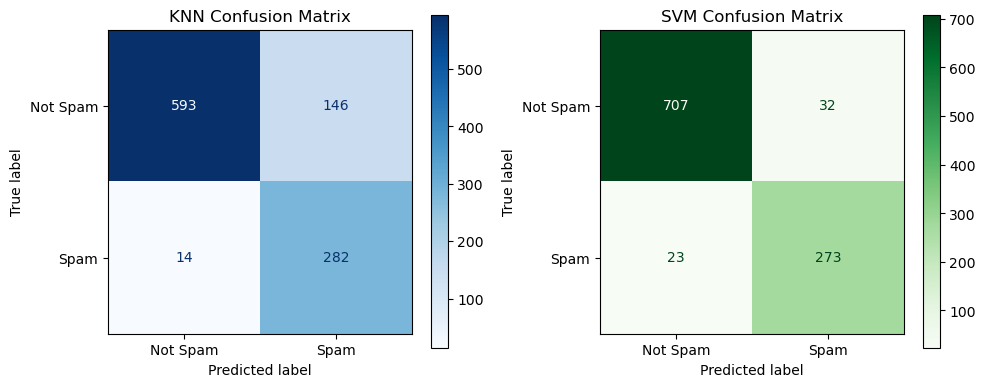

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
# KNN
ConfusionMatrixDisplay.from_predictions(y_test,knn_pred,display_labels=["Not Spam", "Spam"],cmap="Blues",ax=ax[0])
ax[0].set_title("KNN Confusion Matrix")
# SVM
ConfusionMatrixDisplay.from_predictions(y_test,svm_pred,display_labels=["Not Spam", "Spam"],cmap="Greens",ax=ax[1])
ax[1].set_title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
svm = SVC(kernel='linear', probability=True,random_state=42)
svm.fit(X_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [19]:
knn_prob = knn.predict_proba(X_test)[:, 1]
svm_prob = svm.predict_proba(X_test)[:, 1]

In [20]:
from sklearn.metrics import roc_curve, auc
fpr_knn, tpr_knn, _ = roc_curve(y_test, knn_prob)
auc_knn = auc(fpr_knn, tpr_knn)

fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_prob)
auc_svm = auc(fpr_svm, tpr_svm)

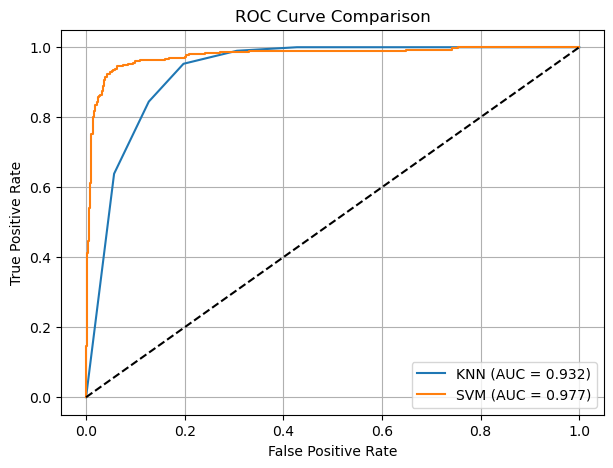

In [21]:
plt.figure(figsize=(7, 5))
plt.plot(fpr_knn,tpr_knn,label=f'KNN (AUC = {auc_knn:.3f})')
plt.plot(fpr_svm,tpr_svm,label=f'SVM (AUC = {auc_svm:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()